# Ⅰ第5回 演習2 ゼロから学習した CNN と，学習済みモデル 3 つを 5 回ずつ比べる

**問い**：学習済みモデルを使うと，第4回の CNN より「差がある」と言えるほど良くなるか．ResNet と ViT で違うか．

| 名前 | モデル | 学習する所 |
|---|---|---|
| CNN | 第4回の CNN（ゼロから・64×64） | 全部 |
| ResNet18 凍結 | 演習1 の凍結 | 最後の層だけ |
| ResNet18 微調整 | 演習1 の微調整 | 全部 |
| ViT 凍結 | ViT-B/16（第4回のオプション課題の ViT を大きくし，ImageNet で学習済み） | 最後の層だけ |

演習1 と同じ手順を関数にまとめてある（`common/transfer.py`）．シード 0〜4 で 5 回ずつ．同じシードなら 4 つとも **同じ写真がテストになる**．

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 1                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/itagakisogo/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 4 つのテスト正解率（5 回の平均）の順位：ResNet18 微調整 ＞ ResNet18 凍結 ＞ ViT 凍結 ＞ CNN
- CNN と ResNet18 凍結に「差がある」と言えるか：言える

## (確認) 転移学習

授業ページの「演習2」を読んでから答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　凍結のとき，学習で変わる重みはどれか
- ア 全部の層
- イ 最後の層（`fc`）だけ
- ウ どの層も変わらない

**Q2**　学習済みモデルに入れる画像を，ImageNet の平均と標準偏差で正規化するのはなぜか
- ア 学習済みモデルが学習したときと同じ入力にするため
- イ 画像を小さくして速くするため
- ウ 写真の色を消すため

**Q3**　微調整で学習率を 0.0001（凍結の 1/10）にするのはなぜか
- ア 学習を速く終わらせるため
- イ 学習済みの重みを大きく壊さないため
- ウ テストの枚数を増やすため

In [4]:
from common.todo import checkpoint, quiz_check
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "イ"
Q2 = "ア"
Q3 = "イ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "86c731cb", "requires_grad = False にした層は動かない．新しく付けた fc だけが学習する"),
    "Q2": (Q2, "eb95be22", "重みは ImageNet の正規化した画像で学習した．同じ形の入力でないと特徴がずれる"),
    "Q3": (Q3, "d0859473", "大きな学習率で全部を動かすと，学習済みの特徴が壊れる"),
})

Q1：正解．requires_grad = False にした層は動かない．新しく付けた fc だけが学習する
Q2：正解．重みは ImageNet の正規化した画像で学習した．同じ形の入力でないと特徴がずれる
Q3：正解．大きな学習率で全部を動かすと，学習済みの特徴が壊れる
全問正解．実験に進んでよい


## (1) 4 つをシード 0〜4 で回す

教員機（M4 Max）で全部 約 40 秒．ノート PC ではその数倍かかる．ViT の重み（330MB）は初回にダウンロードする（準備で済ませていれば不要）．

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common.device import get_device
from common.logger import ResultLogger
from common.mydata import image_dir, run as run_cnn, diff_ratio, verdict
from common.transfer import run
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
IMAGE_DIR = image_dir()
SEEDS = [0, 1, 2, 3, 4]
CONDITIONS = {   # 名前：1 回を実行する関数
    "CNN": lambda seed: run_cnn("CNN", seed=seed, root=IMAGE_DIR, device=device),
    "ResNet18 凍結": lambda seed: run("ResNet18", "freeze", seed=seed, root=IMAGE_DIR, device=device),
    "ResNet18 微調整": lambda seed: run("ResNet18", "finetune", seed=seed, root=IMAGE_DIR, device=device),
    "ViT 凍結": lambda seed: run("ViT", "freeze", seed=seed, root=IMAGE_DIR, device=device),
}
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d5", exercise="ex2", device=device)
rows = []
for name, one_run in CONDITIONS.items():
    for seed in SEEDS:
        r = one_run(seed)
        logger.log_many({k: r[k] for k in ["test_acc", "val_acc_best", "train_sec"]}, condition=f"{IMAGE_DIR.name}_{name}", seed=seed)
        rows.append({"モデル": name, "シード": seed, "テスト正解率": r["test_acc"] * 100, "学習時間(秒)": r["train_sec"],
                     "学習するパラメータ": r.get("params_trained")})
        print(f"{name} シード {seed}：テスト正解率 {r['test_acc'] * 100:.1f}%  ({r['train_sec']:.1f} 秒)")
df = pd.DataFrame(rows)
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

CNN シード 0：テスト正解率 100.0%  (1.5 秒)
CNN シード 1：テスト正解率 93.3%  (1.0 秒)
CNN シード 2：テスト正解率 100.0%  (0.9 秒)
CNN シード 3：テスト正解率 93.3%  (0.9 秒)
CNN シード 4：テスト正解率 100.0%  (0.9 秒)
ResNet18 凍結 シード 0：テスト正解率 80.0%  (7.3 秒)
ResNet18 凍結 シード 1：テスト正解率 93.3%  (4.2 秒)
ResNet18 凍結 シード 2：テスト正解率 60.0%  (4.3 秒)
ResNet18 凍結 シード 3：テスト正解率 100.0%  (4.2 秒)
ResNet18 凍結 シード 4：テスト正解率 93.3%  (4.2 秒)
ResNet18 微調整 シード 0：テスト正解率 100.0%  (8.2 秒)
ResNet18 微調整 シード 1：テスト正解率 100.0%  (6.1 秒)
ResNet18 微調整 シード 2：テスト正解率 100.0%  (6.1 秒)
ResNet18 微調整 シード 3：テスト正解率 100.0%  (6.2 秒)
ResNet18 微調整 シード 4：テスト正解率 100.0%  (6.3 秒)
ViT 凍結 シード 0：テスト正解率 100.0%  (2.6 秒)
ViT 凍結 シード 1：テスト正解率 93.3%  (2.0 秒)
ViT 凍結 シード 2：テスト正解率 100.0%  (2.0 秒)
ViT 凍結 シード 3：テスト正解率 93.3%  (2.0 秒)
ViT 凍結 シード 4：テスト正解率 100.0%  (2.0 秒)
テストは 15 枚．1 枚で 6.7 ポイント動く


## (2) 平均・標準偏差と，CNN との差 ÷ 標準偏差

モデル    CNN  ResNet18 凍結  ResNet18 微調整  ViT 凍結
シード                                          
0    100.0         80.0         100.0   100.0
1     93.3         93.3         100.0    93.3
2    100.0         60.0         100.0   100.0
3     93.3        100.0         100.0    93.3
4    100.0         93.3         100.0   100.0

             テスト正解率       学習時間(秒)     
               mean   std    mean  std
モデル                                   
CNN            97.3   3.7     1.0  0.3
ResNet18 凍結    85.3  15.9     4.8  1.4
ResNet18 微調整  100.0   0.0     6.6  0.9
ViT 凍結         97.3   3.7     2.1  0.3

CNN → ResNet18 凍結：差 -12.0 ポイント ÷ 標準偏差 11.5 = 1.0 → どちらとも言えない（回数を増やして確かめる）
CNN → ResNet18 微調整：差 +2.7 ポイント ÷ 標準偏差 2.6 = 1.0 → どちらとも言えない（回数を増やして確かめる）
CNN → ViT 凍結：差 +0.0 ポイント ÷ 標準偏差 3.7 = 0.0 → 差があるとは言えない


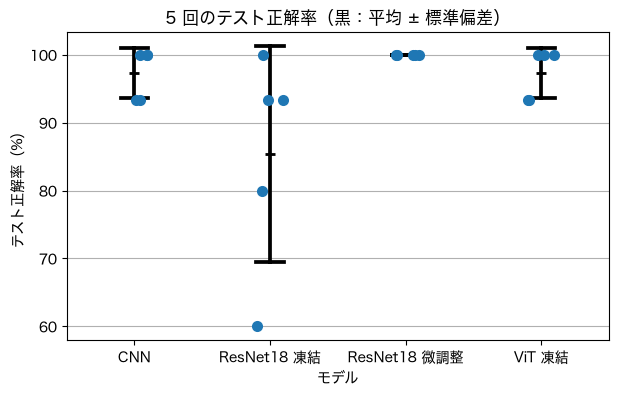

In [6]:
names = list(CONDITIONS)
table = df.pivot(index="シード", columns="モデル", values="テスト正解率")[names]
print(table.round(1).to_string())
print()
print(df.groupby("モデル", sort=False)[["テスト正解率", "学習時間(秒)"]].agg(["mean", "std"]).round(1).to_string())
print()
for name in names[1:]:
    diff, sd, ratio = diff_ratio(table["CNN"], table[name])
    print(f"CNN → {name}：差 {diff:+.1f} ポイント ÷ 標準偏差 {sd:.1f} = {ratio:.1f} → {verdict(ratio)}")

plt.figure(figsize=(7, 4))
sns.stripplot(data=df, x="モデル", y="テスト正解率", size=8, jitter=0.1)
sns.pointplot(data=df, x="モデル", y="テスト正解率", errorbar="sd", color="black", markers="_", capsize=0.2, linestyle="none")
plt.title("5 回のテスト正解率（黒：平均 ± 標準偏差）"); plt.ylabel("テスト正解率（%）"); plt.grid(True, axis="y")
plt.show()

## (3) パラメータの数：全体と，学習した数

In [7]:
from common.mydata import make_model
from common.transfer import build, count_params
n_class = len([d for d in IMAGE_DIR.iterdir() if d.is_dir()])
cnn = sum(p.numel() for p in make_model("CNN", n_class).parameters())
print(f"{'CNN':16s} 全体 {cnn:>11,}｜学習する {cnn:>11,}")
for name, (kind, mode) in {"ResNet18 凍結": ("ResNet18", "freeze"), "ResNet18 微調整": ("ResNet18", "finetune"),
                           "ViT 凍結": ("ViT", "freeze")}.items():
    total, trained = count_params(build(kind, mode, n_class))
    print(f"{name:16s} 全体 {total:>11,}｜学習する {trained:>11,}（{trained / total * 100:.3f}%）")

CNN              全体   2,097,986｜学習する   2,097,986
ResNet18 凍結      全体  11,177,538｜学習する       1,026（0.009%）
ResNet18 微調整     全体  11,177,538｜学習する  11,177,538（100.000%）
ViT 凍結           全体  85,800,194｜学習する       1,538（0.002%）


## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：学習済みモデルで CNN より良くなった人と，ならなかった人がいたか．データの何が違ったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分の (2) の表と判定を見せ，クラスと枚数を言う．根拠になる所：(2) の差 ÷ 標準偏差と，第4回の LLM の正解数
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [8]:
# 問い：学習済みモデルで CNN より良くなった人と，ならなかった人がいたか．データの何が違ったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "全体としては学習済みモデルの方が良いが、データの分布や特徴量の違いによってはCNN の方が良くなる可能性もある"
checkpoint(CP1, "止まる 1")

止まる 1 OK：全体としては学習済みモデルの方が良いが、データの分布や特徴量の違いによってはCNN の方が良くなる可能性もある


## (4) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 予測と比べて，当たったこと・外れたこと：＿＿
2. 自分のタスクに 4 つのどれを使うか．正解率・学習時間・学習するパラメータの数を根拠に書く：＿＿
3. 学習済みモデルは ImageNet（犬・車・食べ物など 1000 種類）で学習した．自分の写真に役立った（または役立たなかった）のはなぜか：＿＿